In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
%load_ext cuml.accel
# %load_ext cudf.pandas

In [3]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep
from threadpoolctl import threadpool_limits

## -- Machine Learning --
from sklearn.ensemble import RandomForestClassifier

from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import (
                                    StandardScaler, OneHotEncoder, LabelEncoder,
                                    KBinsDiscretizer, TargetEncoder as skTE
)

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
    
## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")
train.head()

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [7]:
%%time

ID = 'id'
TARGET = 'is_fraud'

# X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
# y = train[TARGET]
# X_test = test.drop([ID], axis=1); test_id = test[ID]

# print('-'*40)
# print("X      init shape:", X.shape)
# print("X_test init shape:", X_test.shape, "\n")

cat_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = train.drop([ID, TARGET], axis=1).select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols

float_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['float']).columns.tolist()
int_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['int']).columns.tolist()
obj_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['object', 'bool']).columns.tolist()

print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols))
print("init len(float_cols):", len(float_cols))
print("init len(int_cols):", len(int_cols))
print("init len(object_cols):", len(obj_cols))
print("init len(total cols):", len(base_cols), '\n')

init len(cat_cols): 11
init len(num_cols): 13
init len(float_cols): 6
init len(int_cols): 7
init len(object_cols): 11
init len(total cols): 24 

CPU times: user 323 ms, sys: 102 ms, total: 425 ms
Wall time: 422 ms


In [8]:
train_len = len(train)
test_len  = len(test)

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]
int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    'cvv_retry_count', 'day_of_week', 'prior_disputes',
]
int_small = ['txn_count_last_24h', 'cvv_retry_count', 'day_of_week', 'prior_disputes']
int_large = ['card_age_months', 'customer_age', 'time_of_day_hour']

n_unique = train[base_cols].nunique().sort_values()
n_unique

is_new_merchant                     2
used_vpn                            2
is_foreign_transaction              2
ip_country_mismatch                 2
billing_shipping_mismatch           2
is_ai_generated_scam_attempt        2
cvv_retry_count                     4
auth_method                         5
channel                             5
card_type                           5
prior_disputes                      5
day_of_week                         7
device_type                         8
merchant_category                  12
txn_count_last_24h                 12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

In [9]:
## -- Factorize objects for Forest model --

combined = pd.concat([train, test], ignore_index=True)

for c in tqdm(cat_cols, desc="factorize_cats"):
    combined[c], _ = pd.factorize(combined[c], sort=True)
    # combined[c] = combined[c].astype('int32')
    combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

del combined
train.head()

factorize_cats:   0%|          | 0/11 [00:00<?, ?it/s]

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,1,4,0,3,6,0,0,0,0,0,0,0.0


In [10]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,699960.0,349979.500000,202061.191548,0.00,174989.75,349979.50,524969.25,699959.00
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90


In [11]:
def get_class_weights(y):
    """
    y: Current y_labels -> array_like or series
    """
    weights_ = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return weights_

def get_sample_weights(y, y_true):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    """
    classes_ = np.unique(y_true)
    weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
    class_weights = dict(zip(classes_, weights_))
    return np.array([class_weights[label] for label in y])

print("- Helper Functions Ready -")

- Helper Functions Ready -


In [12]:
# import pandas as pd
# from pandas.util import hash_pandas_object

# # Generate hashes
# hash1 = hash_pandas_object(train[base_cols], index=False)
# hash2 = hash_pandas_object(orig[base_cols], index=False)

# # Find rows in orig that are NOT present in train
# new_or_changed_rows = hash2.isin(hash1)

# # Get the actual data for those mismatched rows
# mismatched_orig_data = orig[new_or_changed_rows]
# display(mismatched_orig_data)

In [13]:
## -- Groupby features FE -- ⚠️

from typing import List, Optional, Sequence
from sklearn.base import BaseEstimator, TransformerMixin

class GroupbyAggregator(BaseEstimator, TransformerMixin):
    """
    Leak-free groupby feature generator for CV folds and multiple test sets.
    Fits aggregations on training data only and left-joins them onto any DataFrame.
    """

    def __init__(
        self,
        grouper: str,
        agg_cols: List[str],
        aggs: Sequence[str] = ("mean", "std"),
    ):
        self.grouper = grouper
        self.agg_cols = [c for c in agg_cols if c != grouper]
        self.aggs = aggs
        self.stats_: Optional[pd.DataFrame] = None
        self.group_cols_: List[str] = []

    def fit(self, X: pd.DataFrame, y: Optional[pd.Series] = None) -> "GroupbyAggregator":
        """Compute group aggregations strictly on X (e.g., X_train_fold)."""
        target_cols = [col for col in self.agg_cols if col != self.grouper]
        if not target_cols:
            self.stats_ = None
            self.group_cols_ = []
            return self

        prefix = self.grouper.split("_")[0]
        stats = X.groupby(self.grouper, observed=False)[target_cols].agg(list(self.aggs))

        # Flatten MultiIndex columns into clean feature names
        self.group_cols_ = [
            f"{col}_{prefix}_GROUPBY_{agg}".replace(" ", "")
            for col, agg in stats.columns
        ]
        stats.columns = self.group_cols_
        self.stats_ = stats
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        """Map learned group statistics onto X while preserving its original index."""
        if self.stats_ is None or not self.group_cols_:
            return X.copy()

        # Left merge preserves row order; re-assign original index to prevent resets
        merged = X.merge(self.stats_, on=self.grouper, how="left")
        merged.index = X.index
        return merged

    def transform_many(self, *dfs: pd.DataFrame) -> List[pd.DataFrame]:
        """Convenience helper to transform multiple DataFrames in a single call."""
        return [self.transform(df) for df in dfs]


In [14]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_trn, y_trn = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_trn.copy()
            temp_df_train['target'] = y_trn

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_trn.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [15]:
## -- original_TE with factorization --
from typing import List, Optional, Tuple

def original_fcTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies out-of-fold / external dataset target encoding (TE) from `orig` onto `df`.
    """
    X_df = df.copy()
    orig_df = orig.copy()  # Prevent mutating the caller's original DataFrame

    # 1. Early exit with consistent return signature (DataFrame, list)
    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig_df.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    # 2. Validate features exist in BOTH DataFrames
    valid_features = [
        col for col in features 
        if col in orig_df.columns and col in X_df.columns
    ]
    
    # Separate 'count' from target-dependent aggregations
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Align categorical/object/bool dtypes safely only for needed columns
        if pd.api.types.is_object_dtype(X_df[col]) or \
           isinstance(X_df[col].dtype, pd.CategoricalDtype) or \
           pd.api.types.is_bool_dtype(X_df[col]):
            combined = pd.concat([X_df[col], orig_df[col]], ignore_index=True)
            codes, _ = pd.factorize(combined, sort=True)
            X_df[col] = codes[:len(X_df)]
            orig_df[col] = codes[len(X_df):]

        # Group once per feature instead of once per (feature, agg)
        grouped = orig_df.groupby(col, dropna=False)
        
        # Compute target aggregations in one vectorized pass
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # .map() preserves X_df's exact index and row order
                    new_features_dict[new_col] = X_df[col].map(agg_stats[agg_key])
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        # Handle 'count' separately since it doesn't depend on `target`
        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts = grouped.size()
            new_features_dict[new_col] = X_df[col].map(counts)
            orig_cols.append(new_col)

    # Concatenate all new columns at once to avoid DataFrame fragmentation
    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    # 3. Fill missing values cleanly
    if fill_nan and orig_cols:
        global_mean = orig_df[target].mean()
        global_median = orig_df[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Factorized augment function ready! --')

-- Factorized augment function ready! --


In [16]:
## -- original_TE with objects --
from typing import List, Optional, Tuple

def original_obTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies external dataset target encoding (TE) from `orig` onto `df`
    while preserving original categorical/string dtypes.
    """
    X_df = df.copy()

    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    valid_features = [
        col for col in features 
        if col in orig.columns and col in X_df.columns
    ]
    
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Group directly on raw strings, objects, or categories (observed=True prevents cartesian blowups)
        grouped = orig.groupby(col, dropna=False, observed=True)
        
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # Convert Series to plain dict so CategoricalIndex mismatches don't cause issues
                    mapping_dict = agg_stats[agg_key].to_dict()
                    new_features_dict[new_col] = X_df[col].map(mapping_dict).astype('float32')
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts_dict = grouped.size().to_dict()
            new_features_dict[new_col] = X_df[col].map(counts_dict).astype('float32')
            orig_cols.append(new_col)

    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    if fill_nan and orig_cols:
        global_mean = orig[target].mean()
        global_median = orig[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Object augment function ready! --')

-- Object augment function ready! --


# FEATURE ENGINEERING

In [17]:
# ## -- NUMS_to_CATS (TargetEncoding) -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Features before operation:", len(FEATURES))

# combined = pd.concat([train, test], ignore_index=True)
# ## ------------------------------------------------------------
# # -- Duplicate Nums as Cats --
# nums_to_cats = []

# select_nc = num_cols

# for c in tqdm(select_nc, desc="nums_to_cats"):
#     new_cat = f"{c}_CAT_"
#     combined[new_cat], unique = pd.factorize(combined[c], sort=True)
#     # combined[new_cat] = combined[new_cat].astype('int32') #.astype('category')
#     nums_to_cats.append(new_cat)
# ## ------------------------------------------------------------
# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# # orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Features after operation:", train.shape[1])

In [18]:
## -- Frequency encoding -- ⚠️
combined = pd.concat([train, test], ignore_index=True)

freq_cols = []
select_freq = cat_cols

print("\nCreating frequencies (Safe Global Mapping)...")
for col in select_freq:
    n = f"{col}_FREQ_"
    # print(f"⧗ {n}", end="")
    
    # Calculate frequencies using ONLY train
    freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()
    
    # Map the training-derived frequencies across all datasets safely
    train[n] = train[col].map(freq_map).astype("float32")
    test[n] = test[col].map(freq_map).astype("float32")
    orig[n] = orig[col].map(freq_map).astype("float32")
    
    freq_cols.append(n)
    # print()

print(f"\n *** Total frequency features: {len(freq_cols)}")
train[freq_cols].nunique()


Creating frequencies (Safe Global Mapping)...

 *** Total frequency features: 11


merchant_category_FREQ_               12
card_type_FREQ_                        5
auth_method_FREQ_                      5
channel_FREQ_                          5
device_type_FREQ_                      8
is_foreign_transaction_FREQ_           2
is_new_merchant_FREQ_                  2
used_vpn_FREQ_                         2
ip_country_mismatch_FREQ_              2
billing_shipping_mismatch_FREQ_        2
is_ai_generated_scam_attempt_FREQ_     2
dtype: int64

In [19]:
# ## -- DIGITS extraction -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

# combined = pd.concat([train, test], ignore_index=True)
# digit_cols = []

# for col in num_cols:
#     scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8') #.astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:train_len]
# test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# # orig = combined.iloc[train_len+test_len:]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# # orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# train[digit_cols].nunique()

In [20]:
# # ## -- Ai suggest: DIGITS extraction -- ⚠️
# combined = pd.concat([train, test, orig], ignore_index=True)
# new_digits = {}

# for col in num_cols:
#     is_na = combined[col].isna()
#     scaled = np.rint(np.abs(combined[col].fillna(0)) * 10**4).astype("int64")
    
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         digits = ((scaled // 10**(k + 4)) % 10).astype("int8")
#         digits[is_na] = -1
#         new_digits[dig_col] = digits

# digit_df = pd.DataFrame(new_digits, index=combined.index)

# # Filter constant features based ONLY on train
# train_digits = digit_df.iloc[:train_len]
# unique_counts = train_digits.nunique()
# keep_cols = unique_counts[unique_counts >= 2].index.tolist()

# digit_df = digit_df[keep_cols]

# # Re-attach cleanly without slicing bugs or SettingWithCopyWarning
# train = pd.concat([train.reset_index(drop=True), digit_df.iloc[:train_len].reset_index(drop=True)], axis=1)
# test = pd.concat([test.reset_index(drop=True), digit_df.iloc[train_len:train_len + test_len].reset_index(drop=True)], axis=1)
# orig = pd.concat([orig.reset_index(drop=True), digit_df.iloc[train_len + test_len:].reset_index(drop=True)], axis=1)

# del combined, digit_df, new_digits
# print(f"Total digit features: {len(keep_cols)}\n")
# print(train[keep_cols].nunique())


In [21]:
# def digit_keys(df1, cols=float_cols):
#     df = df1.copy()
#     """How each number is written: six label-free keys per float column."""
#     keys = {}
#     for c in cols:
#         units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
#         integer = units // 100
#         s = pd.Series(integer).astype(str)
#         keys[f"{c}__int"] = integer                                      # 1371
#         keys[f"{c}__int10"] = units // 1000                              # 137
#         keys[f"{c}__tenths"] = units // 10                               # 13713
#         keys[f"{c}__cents"] = units % 100                                # 37
#         keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
#         keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

#     new_df = pd.DataFrame(keys, index=df.index)
#     full_df = pd.concat([df, new_df], axis=1)
#     return full_df, [*keys.keys()]

# train, digit_cols2 = digit_keys(train)
# test, _ = digit_keys(test)
# orig, _ = digit_keys(orig)

# print(train.shape, test.shape)
# train[digit_cols2].nunique()

In [22]:
## -- Cyclic encoding --
cyclic_cols = [] 
cy_cols = ['time_of_day_hour'] # 'txn_count_last_24h'

for col in tqdm(cy_cols):
    for p in [24]:
        # n_s = f"{col}_SINE_{p}"
        # train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
        # test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
        # orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
        # cyclic_cols.append(n_s)

        n_c = f"{col}_COSINE_{p}"
        train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
        test[n_c]  = np.cos(2 * np.pi * test[col] / p).astype('float32')
        orig[n_c]  = np.cos(2 * np.pi * orig[col] / p).astype('float32')
        cyclic_cols.append(n_c)

# NUMS.extend(CYCLICS)

print(f"Cylcic Features created: {len(cyclic_cols)}")
display(train[cyclic_cols].describe().T)

train[cyclic_cols].head()

  0%|          | 0/1 [00:00<?, ?it/s]

Cylcic Features created: 1


,count,mean,std,min,25%,50%,75%,max
time_of_day_hour_COSINE_24,699960.0,-0.014472,0.708309,-1.0,-0.707107,-1.836970e-16,0.707107,1.0


,time_of_day_hour_COSINE_24
0,-0.258819
1,0.965926
2,-0.707107
3,-0.258819
4,0.500000


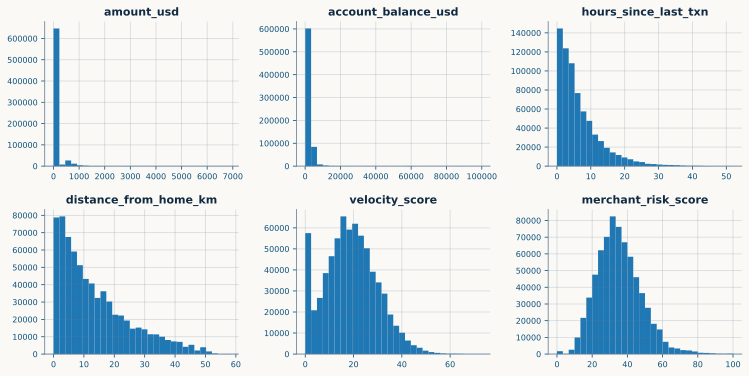

In [23]:
train[float_cols].hist(layout=(2, 3), figsize=(12.5, 6), bins=30)
plt.show()

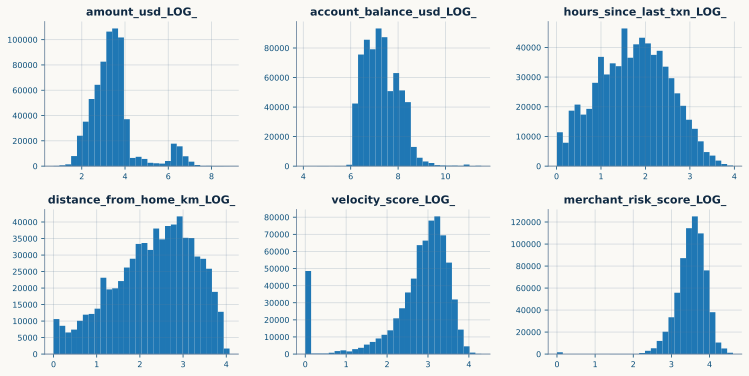

In [24]:
## -- LOG features --
combined = pd.concat([train, test], ignore_index=True)
log_cols = []

 # ["amount_usd ", "account_balance_usd"] + float_cols
for c in float_cols:
    log_c = f"{c}_LOG_"
    combined[log_c] = np.log1p(combined[c])
    log_cols.append(log_c)

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:]

train[log_cols].hist(layout=(2, 3), figsize=(12.5, 6), bins=30)
plt.show()

In [25]:
# ## -- Feature Interactions -- ⚠️

# INTER = []

# combined = pd.concat([train, test], ignore_index=True)
# # ------------------------------------------------------------------------
# combo_2_1 = list(itertools.combinations(cat_cols, 2))
# for c1, c2 in tqdm(combo_2_1, desc="Pairwise Sync Encoding"):
#     n_col = f"Bi_{c1}_X_{c2}".replace(" ", "")
#     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str)
#     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
#     # combined[n_col] = combined[n_col].astype("category")
#     INTER.append(n_col)

# # combo_3_1 = list(itertools.combinations(cat_cols, 3))
# # for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
# #     n_col = f"Tri_{c1}_X_{c2}_X_{c3}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str) + "_" + combined[c3].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# # combo_4_1 = list(itertools.combinations(cat_cols, 4))
# # for c1, c2, c3, c4 in tqdm(combo_4_1, desc='Quadwise Sync Encoding'):
# #     n_col = f"Quad_{c1}_X_{c2}_X_{c3}_X_{c4}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str) + "_" + combined[c3].astype(str) + "_" + combined[c4].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# # combo_1_to_many = list(itertools.product(cat_cols, decimal_digits))
# # for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
# #     n_col = f"Bi2_{c1}_X_{c2}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)
# # ------------------------------------------------------------------------

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len]
# # orig  = combined.iloc[train_len+test_len:]

# # print(f"Total Interaction Features: {INTER}")

# del combined
# train[INTER].head()

In [26]:
## -- Interactions function --
# from typing import Iterable, List, Optional, Sequence, Tuple

# def generate_interaction_features(
#     dfs: List[pd.DataFrame],
#     cols: Optional[List[str]] = None,
#     combo_orders: Sequence[int] = (2, 3),
#     product_lists: Optional[List[List[str]]] = None,
#     as_category: bool = False,
# ) -> Tuple[List[pd.DataFrame], List[str]]:
#     """
#     Generate factorized interaction features across up to 3 DataFrames.

#     Args:
#         dfs: List of DataFrames (1 to 3) to encode together and split back in order.
#         cols: Columns used for n-way combinations when product_lists is not provided.
#         combo_orders: Sequence of combination sizes (allowed values: 2, 3, 4).
#         product_lists: List of 2 column lists for Cartesian product interactions.
#                        When provided, combo_orders and cols are ignored.
#         as_category: Convert resulting integer codes to pandas 'category' dtype.

#     Returns:
#         Tuple containing (list of updated DataFrames in original order, list of new feature names).
#     """
#     # --- 1. Input Validation ---
#     if not (1 <= len(dfs) <= 3):
#         raise ValueError(f"`dfs` must contain between 1 and 3 DataFrames, got {len(dfs)}.")

#     if product_lists is not None:
#         if len(product_lists) != 2:
#             raise ValueError(f"`product_lists` must contain at most 2 lists (and at least 2 for a product), got {len(product_lists)}.")
#     else:
#         if not cols:
#             raise ValueError("`cols` must be provided when `product_lists` is None.")
#         valid_orders = {2, 3, 4}
#         if not combo_orders or not set(combo_orders).issubset(valid_orders):
#             raise ValueError(f"`combo_orders` must only contain integers from {valid_orders}, got {combo_orders}.")

#     # --- 2. Combine DataFrames & Track Split Boundaries ---
#     lengths = [len(df) for df in dfs]
#     combined = pd.concat(dfs, ignore_index=True)

#     # --- 3. Build Specs & Pre-cache String Columns ---
#     prefix_map = {2: "Bi", 3: "Tri", 4: "Quad"}
#     interaction_specs: List[Tuple[str, str, Iterable[Tuple[str, ...]]]] = []

#     if product_lists is not None:
#         all_target_cols = set(product_lists[0]) | set(product_lists[1])
#         interaction_specs.append(
#             ("Prod", "Product Sync Encoding", itertools.product(product_lists[0], product_lists[1]))
#         )
#     else:
#         all_target_cols = set(cols)  # type: ignore[arg-type]
#         for order in sorted(set(combo_orders)):
#             prefix = prefix_map[order]
#             interaction_specs.append(
#                 (prefix, f"{order}-Way Sync Encoding", itertools.combinations(cols, order))  # type: ignore[arg-type]
#             )

#     str_cache = {col: combined[col].astype(str) for col in all_target_cols}

#     # --- 4. Generate Factorized Interaction Features ---
#     new_features = {}
#     for prefix, desc, combos in interaction_specs:
#         for col_tuple in tqdm(list(combos), desc=desc):
#             col_name = f"{prefix}_{'_X_'.join(col_tuple)}".replace(" ", "")

#             combined_series = str_cache[col_tuple[0]]
#             for col in col_tuple[1:]:
#                 combined_series = combined_series + "_" + str_cache[col]

#             codes, _ = pd.factorize(combined_series, sort=True)
#             if as_category:
#                 codes = pd.Categorical(codes)
#             new_features[col_name] = codes

#     inter_df = pd.DataFrame(new_features, index=combined.index)
#     combined = pd.concat([combined, inter_df], axis=1)
#     inter_cols = list(new_features.keys())

#     # --- 5. Split Back Into Original Order ---
#     output_dfs: List[pd.DataFrame] = []
#     start = 0
#     for length in lengths:
#         output_dfs.append(combined.iloc[start : start + length].copy())
#         start += length

#     return output_dfs, inter_cols


In [27]:
## -- Arithmetic features --
combined = pd.concat([train, test], ignore_index=True)

combined['velocity_+_merchant'] = (combined['velocity_score'] + combined['merchant_risk_score'])/100.0
combined['risk_score_X_cvv'] = combined['velocity_+_merchant'] * combined['cvv_retry_count']

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

del combined

print(f"Arithmetic features created!")

Arithmetic features created!


In [28]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=150_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

(699960, 46) <class 'pandas.core.frame.DataFrame'>


In [29]:
## -- Handle optional original table aggregations
USE_ORIGINAL = True
import_cols  = cat_cols

if USE_ORIGINAL: # try 'std' again later ⚠️
    aggs_ = ["count"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_obTE(
        orig, train_X, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_obTE(
        orig, test, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int8")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int8")

print(X.shape, type(X))
X.head()

original_augmenting:   0%|          | 0/11 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/11 [00:00<?, ?it/s]

(699960, 55) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,merchant_category_FREQ_,card_type_FREQ_,auth_method_FREQ_,channel_FREQ_,device_type_FREQ_,is_foreign_transaction_FREQ_,is_new_merchant_FREQ_,used_vpn_FREQ_,ip_country_mismatch_FREQ_,billing_shipping_mismatch_FREQ_,is_ai_generated_scam_attempt_FREQ_,time_of_day_hour_COSINE_24,amount_usd_LOG_,account_balance_usd_LOG_,hours_since_last_txn_LOG_,distance_from_home_km_LOG_,velocity_score_LOG_,merchant_risk_score_LOG_,velocity_+_merchant,risk_score_X_cvv,oTE_merchant_category_count,oTE_card_type_count,oTE_auth_method_count,oTE_channel_count,oTE_device_type_count,oTE_is_foreign_transaction_count,oTE_is_new_merchant_count,oTE_used_vpn_count,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_count
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,142578.0,254857.0,175178.0,206465.0,164691.0,687862.0,593240.0,676295.0,688648.0,690906.0,697661.0,-0.258819,4.129712,7.147048,2.376764,2.932792,1.871802,3.407842,0.347,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,155097.0,345001.0,154020.0,83716.0,237454.0,687862.0,593240.0,676295.0,688648.0,690906.0,697661.0,0.965926,3.251537,8.081475,0.932164,2.643334,3.538057,3.430756,0.633,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,42027.0,345001.0,175178.0,273939.0,27688.0,687862.0,593240.0,23665.0,688648.0,690906.0,697661.0,-0.707107,1.996060,6.954524,0.788457,2.215937,3.605498,3.222868,0.599,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,142578.0,254857.0,210036.0,206465.0,237454.0,687862.0,593240.0,676295.0,688648.0,690906.0,697661.0,-0.258819,3.649099,7.704663,1.813195,2.269028,3.077312,3.758872,0.626,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,1,4,0,3,6,0,0,0,0,0,0,48693.0,345001.0,210036.0,273939.0,80934.0,687862.0,593240.0,676295.0,688648.0,690906.0,697661.0,0.500000,6.484406,8.099269,0.587787,2.540814,3.577948,3.891820,0.828,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 55 columns):
 #   Column                                  Non-Null Count   Dtype   
---  ------                                  --------------   -----   
 0   amount_usd                              699960 non-null  float64 
 1   hours_since_last_txn                    699960 non-null  float64 
 2   txn_count_last_24h                      699960 non-null  int64   
 3   distance_from_home_km                   699960 non-null  float64 
 4   card_age_months                         699960 non-null  int64   
 5   customer_age                            699960 non-null  int64   
 6   account_balance_usd                     699960 non-null  float64 
 7   cvv_retry_count                         699960 non-null  int64   
 8   velocity_score                          699960 non-null  float64 
 9   time_of_day_hour                        699960 non-null  int64   
 10  day_of_week                     

In [31]:
# ## -- Reduce data memory --

# def reduce_memory(df, factorize_first=False):
#     # Use copy() if you want to avoid modifying the original dataframe in place
#     # df = df.copy()

#     old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         col_type = df[c].dtype
#         # Check if type is bool (True or False)
#         if col_type == bool:
#             if factorize_first:
#                 df[c], _ = df[c].factorize(sort=True)
#                 df[c] = df[c].astype('category')
#             else:
#                 df[c] = df[c].astype(str).astype('category')
#         # Check if type is integer
#         elif np.issubdtype(col_type, np.integer):
#             df[c] = pd.to_numeric(df[c], downcast='integer')
#         # Optional: Convert object types with low cardinality to category
#         elif col_type == object or col_type.name == 'category':
#             if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
#                 if factorize_first:
#                     df[c], _ = df[c].factorize(sort=True)
#                     df[c] = df[c].astype('category')
#                 else:
#                     df[c] = df[c].astype('category')
#         # Check if type is float
#         # elif np.issubdtype(col_type, np.floating):
#         #     df[c] = pd.to_numeric(df[c], downcast='float')

#     new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
#     print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

#     return df

# X = reduce_memory(X, factorize_first=True)
# X_test = reduce_memory(X_test, factorize_first=True)
# # orig = reduce_memory(orig)

# print(f"Data memory reduced!")
# gc.collect()

# X.head()

In [32]:
KBIN = KBinsDiscretizer(
    n_bins=10, encode='ordinal', strategy='quantile',
    subsample=len(X)//2, random_state=42,
).set_output(transform='pandas')

X1 = KBIN.fit_transform(X[float_cols], y)
X1.head()

,amount_usd,account_balance_usd,hours_since_last_txn,distance_from_home_km,velocity_score,merchant_risk_score
0,8.0,4.0,7.0,7.0,1.0,3.0
1,4.0,8.0,1.0,5.0,9.0,3.0
2,0.0,3.0,1.0,4.0,9.0,1.0
3,6.0,7.0,5.0,4.0,5.0,7.0
4,9.0,8.0,0.0,5.0,9.0,8.0


# ML TRAINING

In [33]:
# def Trainer_CV(
#     model_name, params, train_df, test_df, features, target, kfold,
#     one_hot_cats=None, use_te=False, use_orig=False, smooth='auto', with_mean=True,
# ):
#     print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
#     t0 = time()

#     oof_preds  = np.zeros(len(train_df))
#     test_preds = np.zeros(len(test_df))

#     knn_scores   = []
#     fold_scores  = []
#     feat_weights = []
#     feat_names   = []

#     # Handle optional original table aggregations securely if flags enable them
#     if use_orig and "original_TE" in globals():
#         cols_import = [c for c in base_cols if c not in ['Arrival Delay in Minutes', 'Departure Delay in Minutes']]
#         feats = features.copy()
#         aggs_ = ["mean"] #, "count", "std", "skew"
#         X_trn, orig_cols = original_TE(
#             orig, train_df, target=TARGET, features=cols_import , aggs=aggs_, fill_nan=True
#         )
#         x_test, _ = original_TE(
#             orig, test_df, target=TARGET, features=cols_import , aggs=aggs_, fill_nan=True
#         )
#         feats.extend(orig_cols)
#         X = X_trn[feats]
#         y = X_trn[target].astype("int32")
#         X_ts = x_test[feats].copy()
#     else:
#         X = train_df[features]
#         y = train_df[target].astype("int32")
#         X_ts = test_df[features].copy()

#     # binary_cols = [c for c in features if X[c].nunique() == 2]

#     for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
#         print(f"\n{"#"*15}")
#         print(f"++ FOLD {idx}/{kfold.n_splits} +++")
#         print(f"{"#"*15}")

#         # Split data for the current fold
#         X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
#         y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
#         X_test = X_ts.copy()

#         # ## -- OPTION A: Concatenate original data --
#         # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
#         # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)

#         # ## -- OPTION B: TE Merge original data --
#         # X_train, X_valid, X_test, NEW_COLS = orig_TE_data_propagate(
#         #     orig,
#         #     X_train,
#         #     X_valid,
#         #     X_test,
#         #     features=base_cols,
#         #     target=TARGET,
#         #     aggs=['mean'], # mean, median, count, std, nunique, max, min
#         #     fill_nan=True,
#         # )

#         # print(f"Category Mean Encoding: {len(cme_features)} | ", end='')
#         # cme_enc = CategoryMeanTransformer(cat_cols=[c])
#         # X_train[n] = cme_enc.fit_transform(X_train, y_train)
#         # X_valid[n] = cme_enc.transform(X_valid)
#         # X_test[n]  = cme_enc.transform(X_test)

#         # nums_lt_10 = [c for c in train.columns if c in num_cols and train[c].nunique() < 10]
#         # grp_feats  = nums_lt_10 # + cat_cols + [, 'Age_//_10']
#         # grp_col    = 'Flight Distance_//_250'
#         # print(f"⚡️ GroupBy_TE({grp_col}) | features ({len(grp_feats)})")
#         # for c in grp_feats: #+comb 'Flight Distance_//_250', 'Age_//_10'
#         #     fe_col = f"_groupby_Dist_{c}"
#         #     X_train[fe_col] = X_train.groupby(grp_col)[c].transform('mean')
#         #     X_valid[fe_col] = X_valid.groupby(grp_col)[c].transform('mean')
#         #     X_test[fe_col]  = X_test.groupby(grp_col)[c].transform('mean')

#         ## -- TE Opt1. -> Using CUSTOM --
#         if use_te:
#             te_cols = nums_to_cats + floor_cols + INTER + digit_cols # # + bin_cols # # #
#             print(f"⚡️ scikit_TE(smooth={smooth}), features({len(te_cols)})")
#             TE = skTE(
#                 target_type='binary',
#                 cv=5,
#                 random_state=42,
#                 smooth=smooth,
#             )
#             te_trn = TE.fit_transform(X_train[te_cols], y_train.to_numpy())
#             te_val = TE.transform(X_valid[te_cols])
#             te_tst = TE.transform(X_test[te_cols])

#             te_names = [f"TE{smooth}_{c}" for c in te_cols]
#             X_train[te_names] = te_trn
#             X_valid[te_names] = te_val
#             X_test[te_names]  = te_tst
    
#             # Drop original features
#             X_train.drop(te_cols, axis=1, inplace=True)
#             X_valid.drop(te_cols, axis=1, inplace=True)
#             X_test.drop(te_cols, axis=1, inplace=True)
#         else:
#             te_cols = []

#         te_features = [c for c in X_train.columns if c.startswith(('TE_', 'oTE_'))]
#         # binary_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
#         # no_scale_cols = one_hot_cats+te_features+binary_cols+['RaceProgress']#+freq_cols

#         # scale_cols = [c for c in X_train.columns if c not in no_scale_cols]

#         ## -- Handle missing numeric data --
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]
#         print(f"train={X_train.shape}, valid={X_valid.shape}")

#         ## -- Define encoders --
#         scaler_enc  = StandardScaler() if with_mean else StandardScaler(with_mean=False)
#         ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
#         num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=9)
#         cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
#         ## ------------------------------------------------------------------------
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]

#         ohe_cols  = [c for c in X_train.columns if c.startswith('ohe_')]
#         only_nums = [c for c in X_train.columns if c not in list(set(one_hot_cats))]
#                     # [c for c in X_train.columns if c not in ohe_map.values()]
#         full_nums = list(set(only_nums+orig_cols)) if use_orig else list(set(only_nums))
#         # num_cols = list(set(X_train.columns) - set(one_hot_cats))

#         num_proc = make_pipeline(scaler_enc)
#         cat_proc = make_pipeline(ohe_enc)
        
#         preprocessor = make_column_transformer(
#             (cat_proc, one_hot_cats),
#             (num_proc, full_nums),
#             remainder='passthrough',
#             n_jobs=-1,
#         )

#         if idx == 1: display(X_train.head(3))

#         ## ------------------------------------------------------------------------
#         if "KNN" in model_name:
#             ## -- Create pipeline --
#             model = make_pipeline(preprocessor, KNeighborsClassifier(**params), verbose=True)
#             ## -- ⚠️ CALIBRATE -> -> ---------------------------------------------------->
#         elif 'MLP' in model_name:
#             model = make_pipeline(preprocessor, MLPClassifier(**params), verbose=True)
#         else:
#             model = make_pipeline(preprocessor, LogisticRegression(**params), verbose=True)

#         ## -- Train Model --
#         # with threadpool_limits(limits=1, user_api='blas'):
        
#         model.fit(X_train, y_train)
#         feat_names.append(model.named_steps['columntransformer'].get_feature_names_out())
#         print(f"⚡️ Total expanded features: {len(feat_names[-1])}")

#         if 'KNN' not in model_name: # Not available for KNN
#             feat_weights.append(model[-1].coefs_[0][0]) 

#         ## -- Predict on validation and test sets --
#         oof_preds[val_idx] = model.predict_proba(X_valid)[:, 1]
#         test_preds += model.predict_proba(X_test)[:, 1] / kfold.n_splits

#         ## -- Fold score --
#         fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
#         fold_scores.append(fold_score)

#         print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")

#         ## -- Clean up memory -- X_valid, X_train
#         # del y_train, y_valid, X_test
#         # gc.collect()

#     # ## -- Average the test predictions
#     # test_preds /= kfold.n_splits

#     ## -- CV results --
#     print(f"\n{'='*50}")
#     print(f"{kfold.n_splits}-FOLD CV: {model_name} | shape:{X_train.shape} -> {len(feat_names[0])}")
#     print(f"{'='*50}")
#     for i, s in enumerate(fold_scores, 1):
#         print(f" • Fold {i} AUC: {s:.6f}")

#     ## -- Final out-of-fold score --
#     oof_score = np.round(roc_auc_score(y, oof_preds), 6)
#     avg_score = np.round(np.mean(fold_scores), 6)
#     std_score = np.round(np.std(fold_scores), 6)

#     print(f"{'-'*50}")
#     print(f"OOF score: {oof_score}")
#     print(f"AVG score: {avg_score} ± {std_score}")
#     print(f"{'-'*50}")

#     total_time = np.round((time()-t0)/60, 2)
#     print(f"Duration: {total_time} mins")

#     return {
#         'oof_preds': oof_preds,
#         'test_preds':test_preds,
#         'score': avg_score,
#         'model': model,
#         'val_data': [X_valid, y_valid],
#         'weights': [feat_names, feat_weights],
#         'total_time': total_time,
#     }

# print("⚙️ Training function ready ⚙️")

In [34]:
# -- Trainer model --

class CFG:
    TE = True if 'digit_cols2' in globals() else False
    BIN = False
    FOLDS = 5
    SEED = 42

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = "RFOREST_gpu" if torch.cuda.is_available() else "RFOREST_cpu"
print(f"🚀 Training {model_name} with {FOLDS } Folds\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    f0 = time()
    # Target encoding
    if CFG.TE:
        # nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
        te_cols  = digit_cols2
        smooth   = 'auto'
        te_names = [f"TE_{smooth}_{col}" for col in te_cols]

        print(f"⚡️ TargetEncoding({len(te_cols)}) • smooth={smooth}")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    ## ------------------------------------------------------------------------
    ## -- Binning --
    if CFG.BIN:
        n_bins    = 10
        bin_cols  = float_cols
        bin_names = [f"BIN{n_bins}_{col}" for col in bin_cols]

        print(f"⚡️ K-Binning({len(bin_cols)}) • n_bins={n_bins}")
        kbins_enc = KBinsDiscretizer(
            n_bins=n_bins, encode='ordinal', strategy='quantile',
            subsample=len(X_trn)//2, random_state=42,
        )

        tr_bin = kbins_enc.fit_transform(X_trn[bin_cols], y_trn)
        va_bin = kbins_enc.transform(X_val[bin_cols])
        ts_bin = kbins_enc.transform(X_tst[bin_cols])
    
        X_trn[bin_names] = tr_bin
        X_val[bin_names] = va_bin
        X_tst[bin_names] = ts_bin
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}")

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    seeder = 42 # + (fold-1)
    params = {
        'n_estimators': 1000, # d=100
        # 'criterion': 'gini',
        'max_depth': 14, # d=None
        'min_samples_leaf': 5, # d=1
        'max_samples': 0.95, # d=1.0
        # 'max_features': None, # d="sqrt"
        # 'max_leaf_nodes': 31,
        'random_state': seeder,
        'verbose': 1,
        # 'n_jobs': -1,
        # 'min_samples_split': 2,
        # 'oob_score': True,
        # min_weight_fraction_leaf=0.0,
        # min_impurity_decrease=0.0,
        # bootstrap=True,
        # warm_start=False,
        # class_weight=None,
        # ccp_alpha=0.0,
        # monotonic_cst=None,
    }

    model = RandomForestClassifier(**params)
    model.fit(X_trn, y_trn)

    # print(model.feature_importances_)
    feat_importances.append(np.asarray(model.feature_importances_))

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    test_preds += model.predict_proba(X_tst)[:, 1]

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = model.n_estimators
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed={seeder}, tree={best_iter}, time={ff}mins ]\n")

test_preds /= FOLDS

model_name = model_name + f"({len(X_trn.columns)})"
feat_names = X_trn.columns

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (s, t, dura) in enumerate(zip(fold_scores, best_iterations, fold_times), 1):
    print(f" • Fold {i} AUC: {s} | tree={t} in {dura}mins")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'tree'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.2f} mins\n")

del X_trn, y_trn

🚀 Training RanFOREST_gpu with 5 Folds

train=(559968, 55), valid=(139992, 55)
### Fold 1/5
# Fold 1 AUC: 0.93487 [ seed=42, tree=1000, time=0.97mins ]

### Fold 2/5
# Fold 2 AUC: 0.93809 [ seed=42, tree=1000, time=0.95mins ]

### Fold 3/5
# Fold 3 AUC: 0.94255 [ seed=42, tree=1000, time=0.95mins ]

### Fold 4/5
# Fold 4 AUC: 0.93765 [ seed=42, tree=1000, time=0.95mins ]

### Fold 5/5
# Fold 5 AUC: 0.9309 [ seed=42, tree=1000, time=0.95mins ]


5-FOLD CV: RanFOREST_gpu(55) | (559968, 55)
 • Fold 1 AUC: 0.93487 | tree=1000 in 0.97mins
 • Fold 2 AUC: 0.93809 | tree=1000 in 0.95mins
 • Fold 3 AUC: 0.94255 | tree=1000 in 0.95mins
 • Fold 4 AUC: 0.93765 | tree=1000 in 0.95mins
 • Fold 5 AUC: 0.9309 | tree=1000 in 0.95mins
--------------------------------------------------
OOF score: 0.93672
AVG score: 0.93681 ± 0.00385
--------------------------------------------------
4.80 mins



In [35]:
# ==================================================
# 5-FOLD CV: RFORESTgpu(55) | (559968, 55)
# ==================================================
#  • Fold 1 AUC: 0.93245 | iter=1 in 0.13mins
#  • Fold 2 AUC: 0.93651 | iter=1 in 0.12mins
#  • Fold 3 AUC: 0.94075 | iter=1 in 0.12mins
#  • Fold 4 AUC: 0.93668 | iter=1 in 0.12mins
#  • Fold 5 AUC: 0.9301 | iter=1 in 0.12mins
# --------------------------------------------------
# OOF score: 0.93519
# AVG score: 0.9353 ± 0.00369
# --------------------------------------------------
# 0.63 mins

In [36]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
RanFOREST_gpu(55)_93681
-------------------------
4.8 mins



,auc,tree,time(min)
fold 1,0.93487,1000,0.97
fold 2,0.93809,1000,0.95
fold 3,0.94255,1000,0.95
fold 4,0.93765,1000,0.95
fold 5,0.93090,1000,0.95


In [38]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000539
1,699961,0.000428
2,699962,0.045684
3,699963,0.001219
4,699964,0.003224


In [39]:
# !rm -r /kaggle/working/

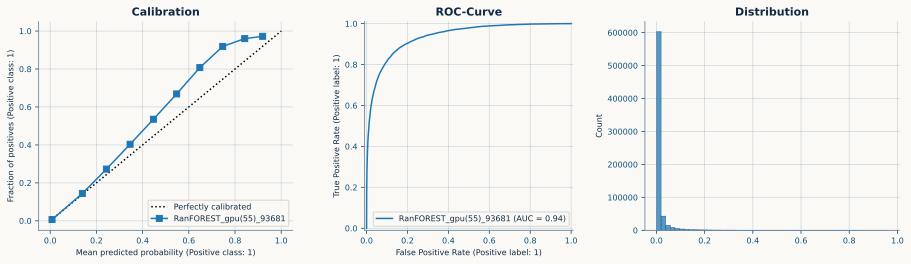

In [40]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 3.5))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout(pad=0.2)
plt.show()

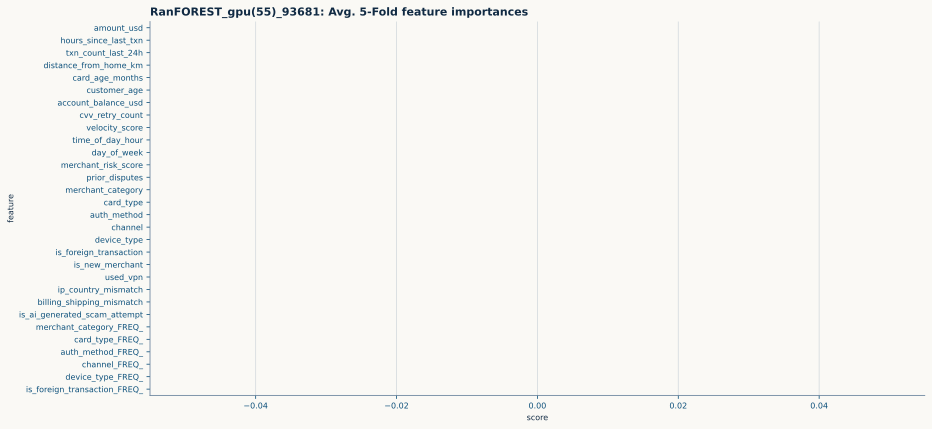

In [41]:
## -- Get model feature importances --
top_n = 30

fi_df = pd.DataFrame({"feature": feat_names, "score": np.mean(feat_importances, axis=0),})\
          .sort_values(by="score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(13, top_n*0.2))
sns.barplot(data=fi_df.head(top_n), x="score", y="feature", palette='plasma')
plt.title(f"{n}: Avg. {FOLDS}-Fold feature importances", loc='left')

plt.tight_layout()
plt.show()

print()

In [42]:
np1 = [2.5, 60.4, 56.9, 305.67]
np2 = [61.3, 5.7, 2.5]
padded_pairs = list(itertools.zip_longest(np1, np2, fillvalue=0))
np.mean(padded_pairs, axis=1)

array([ 31.9  ,  33.05 ,  29.7  , 152.835])

In [43]:
try:
    import shap
except:
    !uv pip install -q shap
    import shap

print(f"Shap version: {shap.__version__}")

Shap version: 0.51.0


In [44]:
# Randomly select 100 rows without replacement
rng = np.random.default_rng(seed=1389)
indices = rng.choice(X_val.shape[0], size=100, replace=False)
val_x = np.array(X_val)[indices]
val_y = np.array(y_val)[indices]

## -- Shap Explainer --
def f(x):
    return model.predict_proba(x)[:, 1]

val_y

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int8)

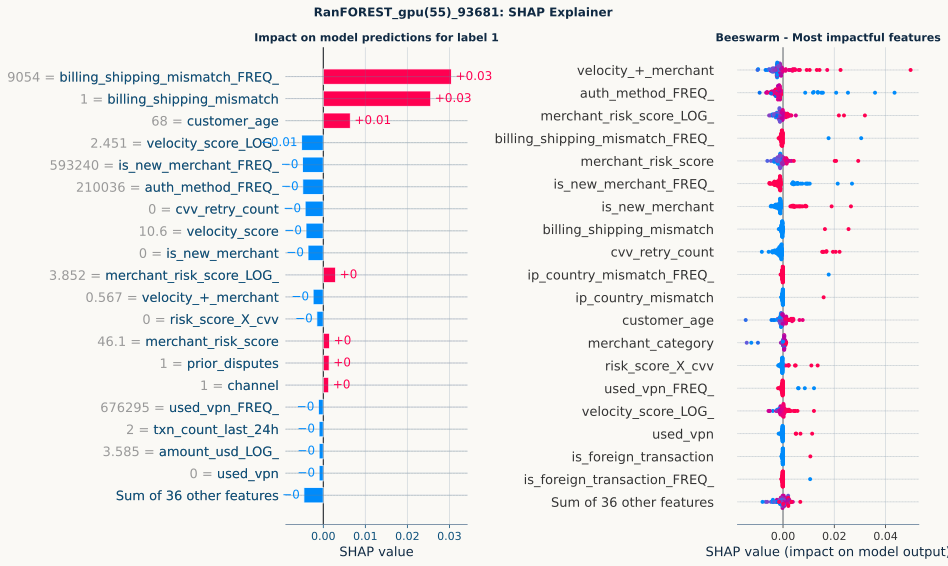

In [45]:
_id = 1
MAX = 20

explainer   = shap.Explainer(f, val_x, feature_names=feat_names, seed=42)
explanation = explainer(val_x, max_evals=max(500, 2*val_x.shape[1]+1))

## -- Bar plot --
plt.subplot(121)
shap.plots.bar(explanation[_id], max_display=MAX, show=False)
plt.title(f"Impact on model predictions for label {val_y[_id]}")

## -- Beeswarm plot --
plt.subplot(122)
shap.plots.beeswarm(
    explanation,
    order=explanation.abs.max(0),
    plot_size=(13, 8),
    max_display=MAX,
    color_bar=False,
    show=False,
)

plt.title("Beeswarm - Most impactful features")
plt.suptitle(f"{n}: SHAP Explainer", size=12, weight="semibold")
plt.tight_layout(pad=1.5)
plt.show()